# Fitting a network to recorded spikes

A simple test of a fitting method is to simulate a "teacher" network, record its
spikes, and fit a "student" network with the same connectome but different connection
strengths. If the student recovers the teacher's strengths from the spikes alone, the
method is worth trying on real recordings.

Here the teacher is a recurrent conductance-based network on a synthetic connectome. The
student is a feedforward network whose inputs are the external input and the teacher's
recorded spikes, and each student neuron has to reproduce the spikes of the
corresponding teacher neuron. This is known as teacher forcing, and it makes each
neuron an independent fit.

The student has the teacher's connectome, but each block of connections between two
cell types has a trainable gain (`ScalingFactorProjection`) that starts away from 1.
The teacher's gains are all 1, so training should bring them back to 1.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.amp import GradScaler

import wiretorch as wt
from wiretorch import visualization as viz
from wiretorch.dataloaders.supervised import SpikeData
from wiretorch.dataloaders.unsupervised import HomogeneousPoissonSpikeDataLoader
from wiretorch.synthetic_connectome import (
    cell_types,
    topology_generators,
    weight_assigners,
)

viz.use_theme()  # the docs' plot style, light and dark
device = "cuda" if torch.cuda.is_available() else "cpu"
np.random.seed(0)
torch.manual_seed(0)

## The teacher

A recurrent network of 300 neurons, 80% excitatory, driven by 150 Poisson inputs. It is
built as in {doc}`synthetic_connectomes`, but without assemblies.

In [2]:
N, N_IN, E, I = 300, 150, 0, 1
types = cell_types.assign_cell_types(N, [0.8, 0.2])
input_types = np.zeros(N_IN, dtype=int)

graph = topology_generators.sparse_graph_generator(
    types, types, [[0.075, 0.075], [0.15, 0.15]]
)
w_rec = weight_assigners.assign_weights_lognormal(
    graph,
    types,
    types,
    None,
    [[0.3, 0.3], [1.8, 1.8]],
    [[0.09, 0.09], [3.24, 3.24]],
    parameter_space="linear",
)
graph = topology_generators.sparse_graph_generator(input_types, types, [[0.16, 0.16]])
w_in = weight_assigners.assign_weights_lognormal(
    graph,
    input_types,
    types,
    None,
    [[0.18, 0.18]],
    [[0.03, 0.03]],
    parameter_space="linear",
)

CELLS = [
    dict(
        name="E",
        cell_id=E,
        tau_mem=85.0,
        theta=-38.0,
        U_reset=-60.0,
        E_L=-60.0,
        g_L=1.35,
    ),
    dict(
        name="I",
        cell_id=I,
        tau_mem=50.0,
        theta=-45.0,
        U_reset=-60.0,
        E_L=-60.0,
        g_L=0.9,
    ),
]
AMPA = dict(name="AMPA", tau_rise=0.1, tau_decay=5.0, E_syn=0.0, g_clip=40.0)
GABA = dict(name="GABA", tau_rise=0.5, tau_decay=6.0, E_syn=-70.0, g_clip=80.0)

rec, ff = wt.make_frozen_projections(
    w_rec, w_in, types, input_types, ["E", "I"], ["input"]
)
teacher = wt.ConductanceLIFNetwork(
    dt=1.0, rec_projections=rec, ff_projections=ff,
    cell_type_indices=types, cell_type_indices_FF=input_types,
    cell_params=CELLS, cell_params_FF=[dict(name="input", cell_id=0)],
    synapse_params=[dict(**AMPA, synapse_id=0, cell_id=E, g_bar=4.0),
                    dict(**GABA, synapse_id=1, cell_id=I, g_bar=8.0)],
    synapse_params_FF=[dict(**AMPA, synapse_id=0, cell_id=0, g_bar=6.0)],
    surrgrad_scale=5.0, batch_size=8,
).to(device)  # fmt: skip

Record 8 trials of 4 s each from the teacher with `SNNInference`, which saves the input
spikes along with the output.

In [3]:
inputs = HomogeneousPoissonSpikeDataLoader(
    firing_rates=np.full(N_IN, 20.0),
    chunk_size=200.0,
    dt=1.0,
    batch_size=8,
    device=device,
)
recording = wt.SNNInference(
    teacher,
    inputs,
    device=device,
    max_chunks=20,
    save_tracked_variables=False,
    progress_bar=False,
).run()
input_spikes = torch.from_numpy(recording["input_spikes"]).float()
teacher_spikes = torch.from_numpy(recording["output_spikes"]).float()
rates = teacher_spikes.mean(dim=(0, 1)) * 1000
print(
    teacher_spikes.shape,
    f"E {rates[types == E].mean():.1f} Hz, I {rates[types == I].mean():.1f} Hz",
)

torch.Size([8, 4000, 300]) E 4.7 Hz, I 26.2 Hz


## The student

The student's input rows are the external inputs followed by the teacher's neurons, so
its input cell types are `input`, `E` and `I`, with the same synapse types as in the
teacher. `make_scaling_factor_projections` splits the teacher's weights into blocks
with one `ScalingFactorProjection` each, and each gain is then perturbed by up to a
factor of 2.

In [4]:
row_types = np.concatenate([input_types, types + 1])  # 0: input, 1: E, 2: I
w_rows = np.concatenate([w_in, w_rec])
_, projections = wt.make_scaling_factor_projections(
    np.zeros((N, N)), w_rows, types, row_types, ["E", "I"], ["input", "E", "I"]
)
rng = np.random.default_rng(1)
with torch.no_grad():
    for projection in projections.values():
        projection.log_sf.fill_(rng.uniform(np.log(0.5), np.log(2.0)))

student = wt.FeedforwardConductanceLIFNetwork(
    dt=1.0, projections=projections,
    cell_type_indices=types, cell_type_indices_FF=row_types,
    cell_params=CELLS,
    cell_params_FF=[dict(name="input", cell_id=0), dict(name="E", cell_id=1), dict(name="I", cell_id=2)],
    synapse_params_FF=[dict(**AMPA, synapse_id=0, cell_id=0, g_bar=6.0),
                       dict(**AMPA, synapse_id=1, cell_id=1, g_bar=4.0),
                       dict(**GABA, synapse_id=2, cell_id=2, g_bar=8.0)],
    surrgrad_scale=5.0, batch_size=8,
).to(device)  # fmt: skip


def gains():
    return {f"{s}→{t}": p.kernel_factor().item() for (s, t), p in projections.items()}


print({k: round(v, 2) for k, v in gains().items()})

{'input→E': 1.02, 'input→I': 1.87, 'E→E': 0.61, 'E→I': 1.86, 'I→E': 0.77, 'I→I': 0.9}


## Training

The data are 200 ms chunks of input rows and target spikes. The loss is the van Rossum
distance, the mean squared difference between the two spike trains after filtering
each with a double exponential. `SNNTrainer` runs the chunks in order with the state
carried over, accumulates gradients over 2 chunks per update, and starts each pass over
the data with a burn-in chunk that only rebuilds the state.

In [5]:
CHUNK = 200
rows = torch.cat([input_spikes, teacher_spikes], dim=2)
chunks = [
    SpikeData(
        input_spikes=rows[:, c : c + CHUNK], target_spikes=teacher_spikes[:, c : c + CHUNK],
        recurrent_input_spikes=None, target_calcium=None, target_rate=None,
    )
    for c in range(0, rows.shape[1], CHUNK)
]  # fmt: skip
EPOCHS = 20
history = []
optimiser = torch.optim.Adam(student.parameters(), lr=0.05)
trainer = wt.SNNTrainer(
    model=student,
    optimizer=optimiser,
    scaler=GradScaler(device, enabled=False),
    dataloader=chunks * EPOCHS,
    loss_functions={
        "van_rossum": wt.VanRossumLoss(
            5.0, 20.0, dt=1.0, window_size=CHUNK, device=device
        )
    },
    loss_weights={"van_rossum": 1.0},
    device=device,
    num_epochs=len(chunks) * EPOCHS,
    chunks_per_update=2,
    log_interval=10**9,
    checkpoint_interval=10**9,
    mixed_precision=False,
    chunks_per_data_epoch=len(chunks),
    burn_in_chunks=1,
    update_callbacks=[lambda: history.append(gains())],
)
trainer.train()
print({k: round(v, 2) for k, v in gains().items()})

  ✓ Model compiled with torch.compile


{'input→E': 1.0, 'input→I': 1.0, 'E→E': 1.0, 'E→I': 1.0, 'I→E': 1.0, 'I→I': 1.0}


<Figure size 770x385 with 1 Axes>
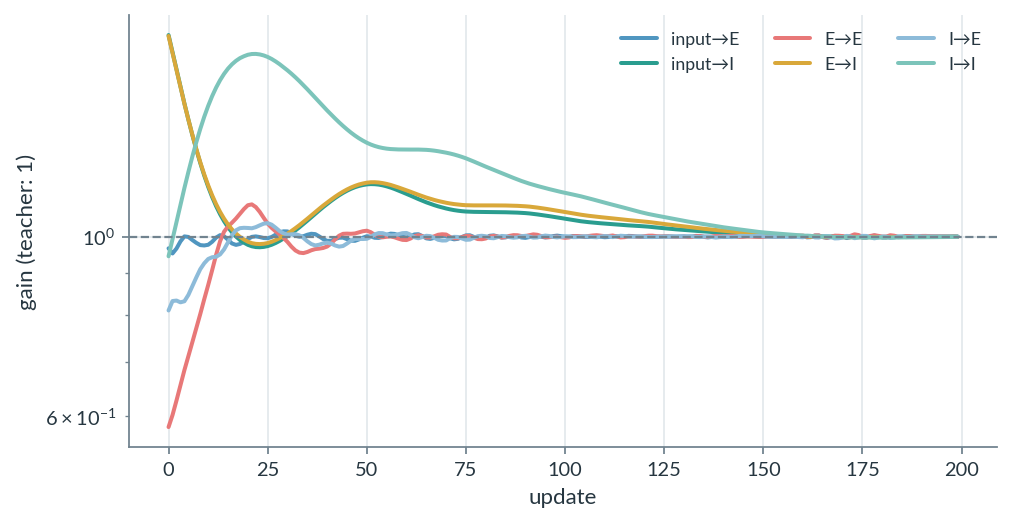
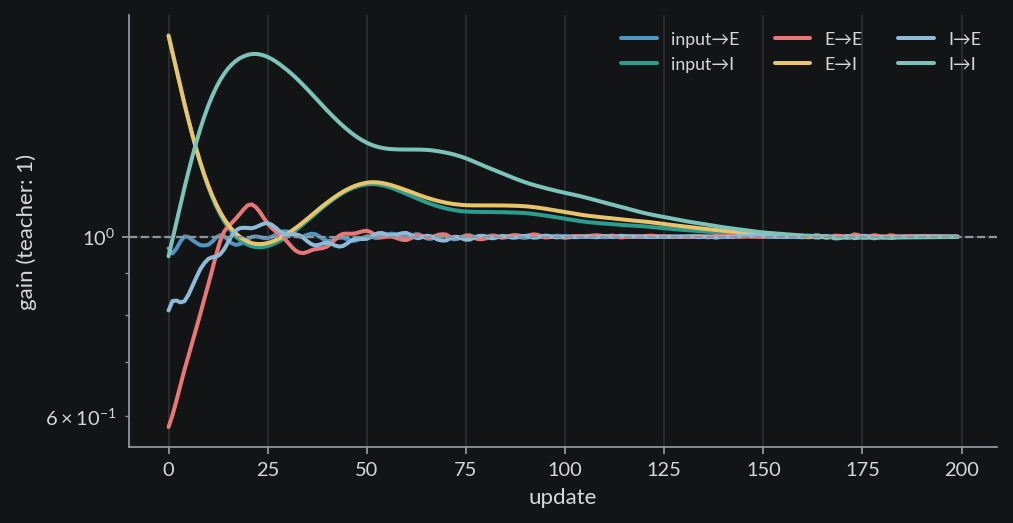

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in history[0]:
    ax.plot([h[name] for h in history], label=name)
ax.axhline(1.0, color=viz.theme.MUTED, ls="--", lw=1)
ax.set_yscale("log"), ax.set_xlabel("update"), ax.set_ylabel("gain (teacher: 1)")
ax.legend(ncol=3, fontsize=8)
plt.show()

## Next steps

To fit more than one gain per block, use `LowRankProjection` or `FullRankProjection`
instead. If only some neurons are recorded, `TwoLayerSNN` models the others as a
recurrent hidden layer ({doc}`../concepts/topologies`). For long runs, give `train` an
output directory, and it will write logs, plots and checkpoints
({doc}`../how-to/checkpoints`).